In [82]:
import numpy as np
from scipy.stats import norm
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [83]:
def simulate_gbm(
    n_paths: int,
    n_steps: int,
    s0: float = 1.0,
    sigma: float = 0.2,
    T: float = 30/365,
    mu: float = 0.0
):
    dt = T / n_steps

    z = np.random.normal(
        size=(n_paths, n_steps)
    )
    increments = (
        (mu - 0.5 * sigma**2) * dt
        + sigma * np.sqrt(dt) * z
    )
    S = np.zeros((n_paths, n_steps + 1))
    S[:, 0] = s0

    S[:, 1:] = s0 * np.exp(
        np.cumsum(increments, axis=1)
    )
    return S

In [84]:
def european_call_option(paths, strike = 1):
    
    terminal_prices = paths[:, -1]
    payoff = np.maximum(terminal_prices - strike, 0)

    return payoff

In [85]:
def black_scholes_call_delta(S, K, tau, sigma, r=0.0):

    S, tau = np.broadcast_arrays(
        np.asarray(S, dtype=float),
        np.asarray(tau, dtype=float)
    )
    safe_tau = np.maximum(tau, 1e-12)
    d1 = (
        np.log(S / K)
        + (r + 0.5 * sigma**2) * safe_tau
    ) / (sigma * np.sqrt(safe_tau))

    delta = norm.cdf(d1)

    # At expiration, use the call's payoff slope
    delta = np.where(
        tau > 0,
        delta,
        np.where(S > K, 1.0, np.where(S < K, 0.0, 0.5)),
    )

    return delta

def black_scholes_hedge(path, strike=1.0, sigma=0.2, T=30/365, r=0.0):

    path = np.asarray(path, dtype=float)

    n_paths, n_prices = path.shape
    n_steps = n_prices - 1

    dt = T / n_steps
    times = np.arange(n_steps) * dt
    time_remaining = T - times

    hedge_positions = black_scholes_call_delta(
        S = path[:, :-1],
        K = strike,
        tau=time_remaining[np.newaxis, :],
        sigma=sigma,
        r=r
    )

    return hedge_positions

In [86]:
def evaluate_hedge(
        paths,
        hedge_positions,
        strike = 1.0,
        transaction_cost_rate = 0.001,
):
    
    price_changes = paths[:, 1:] - paths[:, :-1]

    trading_gains = torch.sum(
        price_changes * hedge_positions,
        dim = 1,
    )
    previous_positions = torch.cat(
        [
            torch.zeros_like(hedge_positions[:, :1]),
            hedge_positions[:, :-1],
        ],
        dim=1
    )
    trades = hedge_positions - previous_positions

    transaction_costs = torch.sum(
        transaction_cost_rate 
        * paths[:, :-1]
        * torch.abs(trades),
        dim = 1
    )
    option_payoff = torch.clamp(
        paths[:, -1] - strike, 
        min= 0.0,
    )

    net_pnl = (
        trading_gains
        - transaction_costs
        - option_payoff
    )

    return {
        "trading_gains": trading_gains,
        "transaction_costs": transaction_costs,
        "option_payoff": option_payoff,
        "net_pnl": net_pnl,
    }

In [88]:
class StandardDeepHedgingNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(4, 32),
            nn.ReLU(),

            nn.Linear(32, 32),
            nn.ReLU(),

            nn.Linear(32, 32),
            nn.ReLU(),

            nn.Linear(32, 32),
            nn.ReLU(),

            nn.Linear(32, 1),
            nn.Tanh()
        )

    def forward(self, features, bs_delta):
        
        adjustments = self.network(features).squeeze(-1)
        hedge_positions = bs_delta + adjustments
        return hedge_positions

In [89]:
def black_scholes_delta_torch(S, K, tau, sigma, r=0.0):

    tau = torch.as_tensor(
            tau,
            dtype=S.dtype,
            device=S.device,
    )
    d1 = (
        torch.log(S / K)
        + (r + 0.5 * sigma ** 2) * tau
    ) / (sigma * torch.sqrt(tau))

    return torch.special.ndtr(d1)

In [90]:
def standard_deep_hedge(
        model,
        paths,
        strike = 1.0,
        sigma = 0.2,
        T = 30 / 365,
        r = 0.0
):
    n_paths, n_prices = paths.shape
    n_steps = n_prices - 1
    dt = T / n_steps

    current_position = torch.zeros(
        n_paths,
        dtype=paths.dtype,
        device=paths.device
    )

    all_positions = []

    for step in range(n_steps):

        S = paths[:, step]
        tau = T - step * dt
        bs_delta = black_scholes_delta_torch(
            S, strike, tau, sigma, r
        )

        features = torch.stack(
            [
                torch.log(S/strike),
                torch.full_like(S, tau),
                torch.full_like(S, sigma),
                current_position
            ],
            dim = 1
        )
        target_position = model(features, bs_delta)
        all_positions.append(target_position)

        current_position = target_position

    return torch.stack(all_positions, dim=1)

In [91]:
def train_standard_hedge_model(n_paths = 10000, 
                                epochs = 200, 
                                strike = 1.0,
                                sigma = 0.2,
                                T = 30/365,
                                transaction_cost_rate = 0.001,
                                lambda_ = 1.0
                            ):

    
    model = StandardDeepHedgingNN()
    optimizer = optim.Adam(model.parameters(), lr = 1e-3)

    loss_history = []

    for epoch in range(epochs):

        paths_np = simulate_gbm(
            n_paths=n_paths,
            n_steps=30,
            s0=strike,
            sigma=sigma,
            T = T,
            mu=0.0 
        )
        paths = torch.tensor(paths_np, dtype=torch.float32)

        hedge_positions = standard_deep_hedge(model=model, paths=paths, strike=strike, sigma=sigma, T=T)

        performance = evaluate_hedge(paths, hedge_positions, strike, transaction_cost_rate)

        net_pnl = performance["net_pnl"]

        loss = torch.mean(torch.exp(-lambda_ * net_pnl))

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())

        if (epoch + 1) % 20 == 0:
            print(
                f"Iteration: {epoch + 1} / {epochs}, "
                f"Loss: {loss.item():.6f}"
            )

    return model, loss_history

Iteration: 20 / 200, Loss: 1.025161
Iteration: 40 / 200, Loss: 1.025294
Iteration: 60 / 200, Loss: 1.025465
Iteration: 80 / 200, Loss: 1.025002
Iteration: 100 / 200, Loss: 1.025044
Iteration: 120 / 200, Loss: 1.024779
Iteration: 140 / 200, Loss: 1.024971
Iteration: 160 / 200, Loss: 1.024413
Iteration: 180 / 200, Loss: 1.023930
Iteration: 200 / 200, Loss: 1.023613


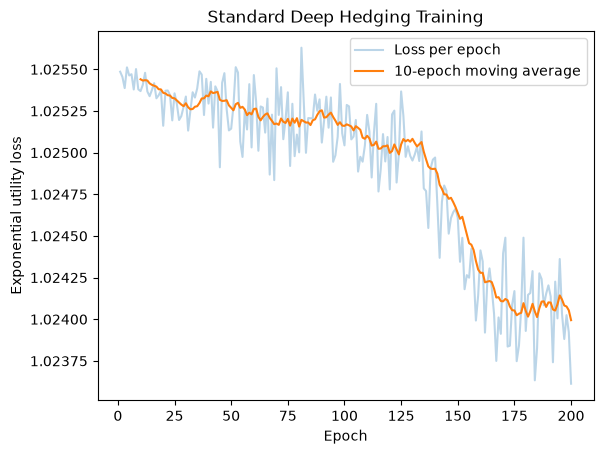

In [92]:
model, loss_history = train_standard_hedge_model()
window = 10

smoothed_loss = np.convolve(
    loss_history,
    np.ones(window) / window,
    mode="valid",
)

plt.plot(
    range(1, len(loss_history) + 1),
    loss_history,
    alpha=0.3,
    label="Loss per epoch",
)

plt.plot(
    range(window, len(loss_history) + 1),
    smoothed_loss,
    label="10-epoch moving average",
)

plt.xlabel("Epoch")
plt.ylabel("Exponential utility loss")
plt.title("Standard Deep Hedging Training")
plt.legend()
plt.show()

In [94]:
class NoTransactionBandNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.hidden = nn.Sequential(
            nn.Linear(3, 32),
            nn.ReLU(),

            nn.Linear(32, 32),
            nn.ReLU(),

            nn.Linear(32, 32),
            nn.ReLU(),

            nn.Linear(32, 32),
            nn.ReLU(),
        )
        self.output = nn.Linear(32, 2)
        nn.init.constant_(self.output.bias, -3.0)


    def forward(self, features, bs_delta):

        raw_widths = self.output(self.hidden(features))
        widths = F.softplus(raw_widths)

        lower_band = bs_delta - widths[:, 0]
        upper_band = bs_delta + widths[:, 1]

        return lower_band, upper_band

In [95]:
def no_transaction_band_hedge(
        model,
        paths,
        strike = 1.0,
        sigma = 0.2,
        T = 30 / 365,
        r = 0.0
):
    n_paths, n_prices = paths.shape
    n_steps = n_prices - 1
    dt = T / n_steps

    current_position = torch.zeros(
        n_paths,
        dtype=paths.dtype,
        device=paths.device
    )

    all_positions = []

    for step in range(n_steps):

        S = paths[:, step]
        tau = T - step * dt
        bs_delta = black_scholes_delta_torch(
            S, strike, tau, sigma, r
        )

        features = torch.stack(
            [
                torch.log(S/strike),
                torch.full_like(S, tau),
                torch.full_like(S, sigma),
            ],
            dim = 1
        )
        lower_band, upper_band = model(features, bs_delta)
        next_position = torch.minimum(
            torch.maximum(current_position, lower_band),
            upper_band,
        )

        all_positions.append(next_position)
        current_position = next_position

    return torch.stack(all_positions, dim=1)

In [96]:
def train_no_transaction_band_model(
    n_paths=10000,
    epochs=200,
    strike=1.0,
    sigma=0.2,
    T=30 / 365,
    transaction_cost_rate=0.001,
    lambda_=1.0,
):

    model = NoTransactionBandNN()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)

    loss_history = []

    for epoch in range(epochs):

        # 1. Generate fresh simulated stock-price paths.
        paths_np = simulate_gbm(
            n_paths=n_paths,
            n_steps=30,
            s0=1.0,
            sigma=sigma,
            T=T,
            mu=0.0,
        )

        paths = torch.tensor(
            paths_np,
            dtype=torch.float32,
        )

        # 2. Choose hedge positions using the band strategy.
        hedge_positions = no_transaction_band_hedge(
            model=model,
            paths=paths,
            strike=strike,
            sigma=sigma,
            T=T,
        )

        # 3. Evaluate gains, trading costs and option liability.
        performance = evaluate_hedge(
            paths=paths,
            hedge_positions=hedge_positions,
            strike=strike,
            transaction_cost_rate=transaction_cost_rate,
        )

        net_pnl = performance["net_pnl"]

        # 4. Minimize exponential-utility loss.
        loss = torch.mean(torch.exp(-lambda_ * net_pnl))

        # 5. Update the network.
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        loss_history.append(loss.item())

        if (epoch + 1) % 20 == 0:
            print(
                f"Iteration: {epoch + 1}/{epochs}, "
                f"Loss: {loss.item():.6f}"
            )

    return model, loss_history

Iteration: 20/200, Loss: 1.024604
Iteration: 40/200, Loss: 1.024479
Iteration: 60/200, Loss: 1.024402
Iteration: 80/200, Loss: 1.024110
Iteration: 100/200, Loss: 1.023621
Iteration: 120/200, Loss: 1.023871
Iteration: 140/200, Loss: 1.023890
Iteration: 160/200, Loss: 1.023469
Iteration: 180/200, Loss: 1.023828
Iteration: 200/200, Loss: 1.023675


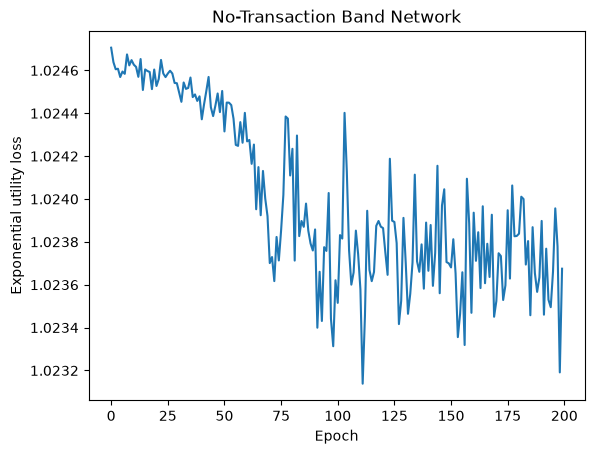

In [97]:
band_model, band_loss_history = (
    train_no_transaction_band_model()
)

plt.plot(band_loss_history)
plt.xlabel("Epoch")
plt.ylabel("Exponential utility loss")
plt.title("No-Transaction Band Network")
plt.show()

In [98]:
validation_paths_np = simulate_gbm(
    n_paths=10_000,
    n_steps=30,
    s0=1.0,
    sigma=0.2,
    T=30 / 365,
    mu=0.0,
)

validation_paths = torch.tensor(
    validation_paths_np,
    dtype=torch.float32,
)

# Baseline: ordinary Black-Scholes delta hedging.
bs_positions_np = black_scholes_hedge(validation_paths_np)

bs_positions = torch.tensor(
    bs_positions_np,
    dtype=torch.float32,
)
with torch.no_grad():
    standard_positions = standard_deep_hedge(
        model=model,
        paths=validation_paths,
        strike=1.0,
        sigma=0.2,
        T=30 / 365,
    )

    band_positions = no_transaction_band_hedge(
        model=band_model,
        paths=validation_paths,
        strike=1.0,
        sigma=0.2,
        T=30 / 365,
    )

bs_results = evaluate_hedge(
    paths=validation_paths,
    hedge_positions=bs_positions,
    strike=1.0,
    transaction_cost_rate=0.001,
)

standard_results = evaluate_hedge(
    validation_paths,
    standard_positions,
    strike=1.0,
    transaction_cost_rate=0.001,
)

band_results = evaluate_hedge(
    validation_paths,
    band_positions,
    strike=1.0,
    transaction_cost_rate=0.001,
)
# Strategy that never trades or holds any shares.
no_hedge_positions = torch.zeros_like(bs_positions)

no_hedge_results = evaluate_hedge(
    paths=validation_paths,
    hedge_positions=no_hedge_positions,
    strike=1.0,
    transaction_cost_rate=0.001,
)

report_results("Never hedge", no_hedge_results)
report_results("Black-Scholes", bs_results)
report_results("Standard Deep Hedging NN", standard_results)
report_results("No-Transaction Band NN", band_results)


Never hedge
Exponential loss: 1.024026
Mean P&L:         -0.023133
Mean transaction costs: 0.000000

Black-Scholes
Exponential loss: 1.025408
Mean P&L:         -0.025083
Mean transaction costs: 0.002221

Standard Deep Hedging NN
Exponential loss: 1.024054
Mean P&L:         -0.023541
Mean transaction costs: 0.000634

No-Transaction Band NN
Exponential loss: 1.023785
Mean P&L:         -0.023231
Mean transaction costs: 0.000293


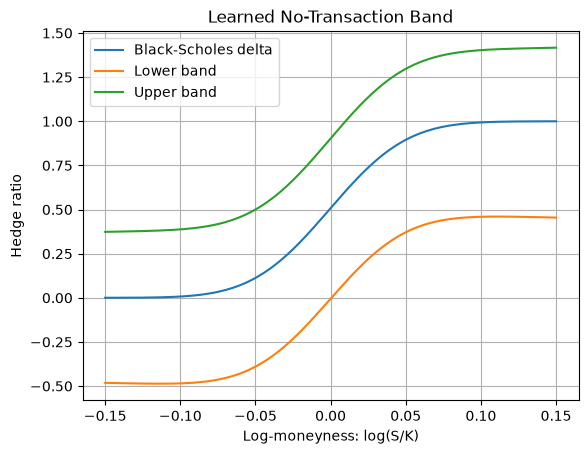

In [99]:
band_model.eval()

log_moneyness = torch.linspace(-0.15, 0.15, 300)
S = torch.exp(log_moneyness)

tau = torch.full_like(S, 15 / 365)
sigma_values = torch.full_like(S, 0.2)

features = torch.stack(
    [log_moneyness, tau, sigma_values],
    dim=1,
)

with torch.no_grad():
    bs_delta = black_scholes_delta_torch(
        S, 1.0, 15 / 365, 0.2
    )

    lower_band, upper_band = band_model(
        features, bs_delta
    )

plt.plot(
    log_moneyness.numpy(),
    bs_delta.numpy(),
    label="Black-Scholes delta",
)
plt.plot(
    log_moneyness.numpy(),
    lower_band.numpy(),
    label="Lower band",
)
plt.plot(
    log_moneyness.numpy(),
    upper_band.numpy(),
    label="Upper band",
)

plt.xlabel("Log-moneyness: log(S/K)")
plt.ylabel("Hedge ratio")
plt.title("Learned No-Transaction Band")
plt.legend()
plt.grid(True)
plt.show()